# Model 9: Hepatitis C category classification with Gaussian Naive Bayes

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

Hepatitis C is a viral infection of the liver that, left alone, moves through stages: an inflamed liver, then fibrosis, where scar tissue starts replacing healthy tissue, then cirrhosis, where the scarring is so extensive that the liver stops working. The stage is confirmed with a biopsy or an elastography, both of which need a specialist. A routine blood panel, on the other hand, is cheap and available anywhere, and the question this notebook answers is whether the ten values of that panel are enough to tell a healthy blood donor from a patient at each stage of the disease, so that the assistant of the project can answer "what does this blood panel suggest" with a category.

The dataset is the hepatitis C file published on Kaggle by fedesoriano, from the UCI repository, with 615 people. Each row is one blood panel with the age, the sex and ten laboratory values, and a category that says whether the person is a blood donor or a patient with hepatitis, fibrosis or cirrhosis.

The technique is Gaussian Naive Bayes, taught in week ten. It uses the theorem of Bayes to turn the probability of seeing a given lab value in each class into the probability of each class given the lab values, under the assumption that the labs are independent of each other inside a class, which is what "naive" means, and that each lab follows a normal bell inside each class, which is what "Gaussian" means. That second assumption is checked and then handled in this notebook, because liver enzymes are not shaped like a bell.

### Libraries

In [1]:
# Dataset handling
import os
import kagglehub
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline

# Split, validation, evaluation and persistence
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             balanced_accuracy_score, recall_score, precision_score)
import joblib

%matplotlib inline

RANDOM_STATE = 42

# Folder shared by every model of the project, read later by the REST API
MODELS_DIR = os.path.join('..', 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

/home/jony/ai-project/env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Understanding (CRISP-DM 2)

The dataset is downloaded through kagglehub, which caches it locally and returns the folder, so the cell works unchanged on a local machine and in Google Colab.

In [2]:
path = kagglehub.dataset_download('fedesoriano/hepatitis-c-dataset')
print('Path to dataset files:', path)
hepatitis = pd.read_csv(os.path.join(path, 'HepatitisCdata.csv'))
hepatitis.head()

Path to dataset files: /home/jony/.cache/kagglehub/datasets/fedesoriano/hepatitis-c-dataset/versions/1


,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


Each row is one person. The first column is an unnamed row number carried over from the original file and carries no information. `Category` is the target, written as a code and a name, `Age` is in years, `Sex` is m or f, and the ten remaining columns are the blood panel: `ALB` albumin, `ALP` alkaline phosphatase, `ALT` and `AST` two liver enzymes that leak into the blood when liver cells are damaged, `BIL` bilirubin, `CHE` cholinesterase, `CHOL` cholesterol, `CREA` creatinine, `GGT` a third liver enzyme, and `PROT` total protein. The first five rows are all 32 year old male blood donors.

In [3]:
# Drop the row number column, then size, types and missing values
hepatitis = hepatitis.drop(columns=['Unnamed: 0'])
print("Rows and columns:", hepatitis.shape)
hepatitis.info()
print("Duplicated rows:", hepatitis.duplicated().sum())

Rows and columns: (615, 13)
<class 'pandas.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Category  615 non-null    str    
 1   Age       615 non-null    int64  
 2   Sex       615 non-null    str    
 3   ALB       614 non-null    float64
 4   ALP       597 non-null    float64
 5   ALT       614 non-null    float64
 6   AST       615 non-null    float64
 7   BIL       615 non-null    float64
 8   CHE       615 non-null    float64
 9   CHOL      605 non-null    float64
 10  CREA      615 non-null    float64
 11  GGT       615 non-null    float64
 12  PROT      614 non-null    float64
dtypes: float64(10), int64(1), str(2)
memory usage: 62.6 KB
Duplicated rows: 0


There are 615 people and 13 columns after dropping the row number. `Category` and `Sex` are text, everything else is numeric. Five labs have missing values: `ALP` is missing in 18 rows, `CHOL` in 10, and `ALB`, `ALT` and `PROT` in one each. No row is duplicated.

In [4]:
hepatitis.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,615.0,47.41,10.06,19.00,39.00,47.00,54.00,77.00
ALB,614.0,41.62,5.78,14.90,38.80,41.95,45.20,82.20
ALP,597.0,68.28,26.03,11.30,52.50,66.20,80.10,416.60
ALT,614.0,28.45,25.47,0.90,16.40,23.00,33.08,325.30
AST,615.0,34.79,33.09,10.60,21.60,25.90,32.90,324.00
BIL,615.0,11.40,19.67,0.80,5.30,7.30,11.20,254.00
CHE,615.0,8.20,2.21,1.42,6.94,8.26,9.59,16.41
CHOL,605.0,5.37,1.13,1.43,4.61,5.30,6.06,9.67
CREA,615.0,81.29,49.76,8.00,67.00,77.00,88.00,1079.10
GGT,615.0,39.53,54.66,4.50,15.70,23.30,40.20,650.90


The table gives the count, the mean, the standard deviation, the minimum, the three quartiles and the maximum of each numeric column. Age runs from 19 to 77 with a median of 47. The labs with a mean far above the median are the ones with a long tail: `ALT` has a median of 23 and a maximum of 325, `AST` a median of 26 and a maximum of 324, `BIL` a median of 7.3 and a maximum of 254, `GGT` a median of 23 and a maximum of 651, and `CREA` a median of 77 and a maximum of 1,079. Those extremes are the sick patients, since a damaged liver pours enzymes into the blood, and the shape of those columns is the central issue for the technique, examined below.

In [5]:
# The target and the sex column
print(hepatitis['Category'].value_counts())
print()
print(hepatitis['Sex'].value_counts())

Category
0=Blood Donor             533
3=Cirrhosis                30
1=Hepatitis                24
2=Fibrosis                 21
0s=suspect Blood Donor      7
Name: count, dtype: int64

Sex
m    377
f    238
Name: count, dtype: int64


The categories are very unbalanced: 533 blood donors, 30 patients with cirrhosis, 24 with hepatitis, 21 with fibrosis, and 7 people coded as suspect blood donors. The suspect group is not a diagnosis, it is a flag the original study put on donors whose panel looked abnormal without a confirmed disease, so it cannot be predicted and it cannot be merged with either side. Those 7 rows are removed. The file is 61 percent male.

The sick classes together are 75 people against 533 donors, so a model that answers "donor" to everyone is right 88 percent of the time. Accuracy is therefore not the score to read here, and the evaluation reports the confusion matrix and the recall of each sick class.

In [6]:
# Where the missing labs are
missing_rows = hepatitis[hepatitis.isna().any(axis=1)]
print("Rows with at least one missing lab:", len(missing_rows))
print(missing_rows['Category'].value_counts())

Rows with at least one missing lab: 26
Category
2=Fibrosis       9
0=Blood Donor    7
3=Cirrhosis      6
1=Hepatitis      4
Name: count, dtype: int64


Of the 26 rows with a missing lab, 19 belong to the sick classes: 9 fibrosis, 6 cirrhosis and 4 hepatitis. Dropping those rows would remove a quarter of the 75 sick patients and almost half of the fibrosis group, so the gaps are filled instead with the median of each lab, in the preparation section. The median is used rather than the mean because of the long tails seen in the summary table.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

The exploration asks two questions: which labs separate the four categories, and whether each lab looks like a normal bell, since that is what Gaussian Naive Bayes assumes.

In [7]:
# Remove the suspect donors and simplify the category names
SUSPECT = '0s=suspect Blood Donor'
hepatitis = hepatitis[hepatitis['Category'] != SUSPECT].copy()
hepatitis['Category'] = hepatitis['Category'].str.split('=').str[1]
CLASSES = ['Blood Donor', 'Hepatitis', 'Fibrosis', 'Cirrhosis']
print("Rows kept:", len(hepatitis))
print(hepatitis['Category'].value_counts().reindex(CLASSES))

Rows kept: 608
Category
Blood Donor    533
Hepatitis       24
Fibrosis        21
Cirrhosis       30
Name: count, dtype: int64


608 people remain, with the four categories named plainly and ordered from healthy to most severe.

In [8]:
# Median of each lab by category
LABS = ['ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']
hepatitis.groupby('Category')[LABS].median().reindex(CLASSES).round(1)

,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
Category,,,,,,,,,,
Blood Donor,42.2,66.7,23.1,24.8,6.9,8.4,5.4,78.0,21.4,72.2
Hepatitis,43.5,34.6,15.2,47.2,13.0,9.5,5.1,72.2,45.6,73.6
Fibrosis,41.0,39.6,34.0,70.0,13.0,8.6,4.6,71.4,72.2,76.1
Cirrhosis,33.0,80.0,5.6,92.9,34.0,3.4,3.9,68.5,96.4,70.0


Reading the medians down the severity ladder tells the clinical story. `AST` rises from 25 in donors to 47 in hepatitis, 70 in fibrosis and 93 in cirrhosis, and `GGT` from 21 to 46, 72 and 96, so the two enzymes climb with every stage. `BIL` stays near 7 in donors and 13 in the two middle stages and jumps to 34 in cirrhosis, and the opposite happens to `CHE`, which drops from 8.4 to 3.4, and to `ALB`, from 42 to 33, because a scarred liver stops producing those proteins. `ALT` behaves differently, high in fibrosis at 34 and very low in cirrhosis at 5.6, since by the last stage there are few liver cells left to leak it. `ALP` is the odd one, low in hepatitis and fibrosis at 35 and 40 and high in cirrhosis at 80. `CREA`, `CHOL` and `PROT` barely move between the classes.

The picture is that cirrhosis is far from the donors on several labs at once, while hepatitis and fibrosis sit between them and close to each other, so the middle two stages are where the model will struggle.

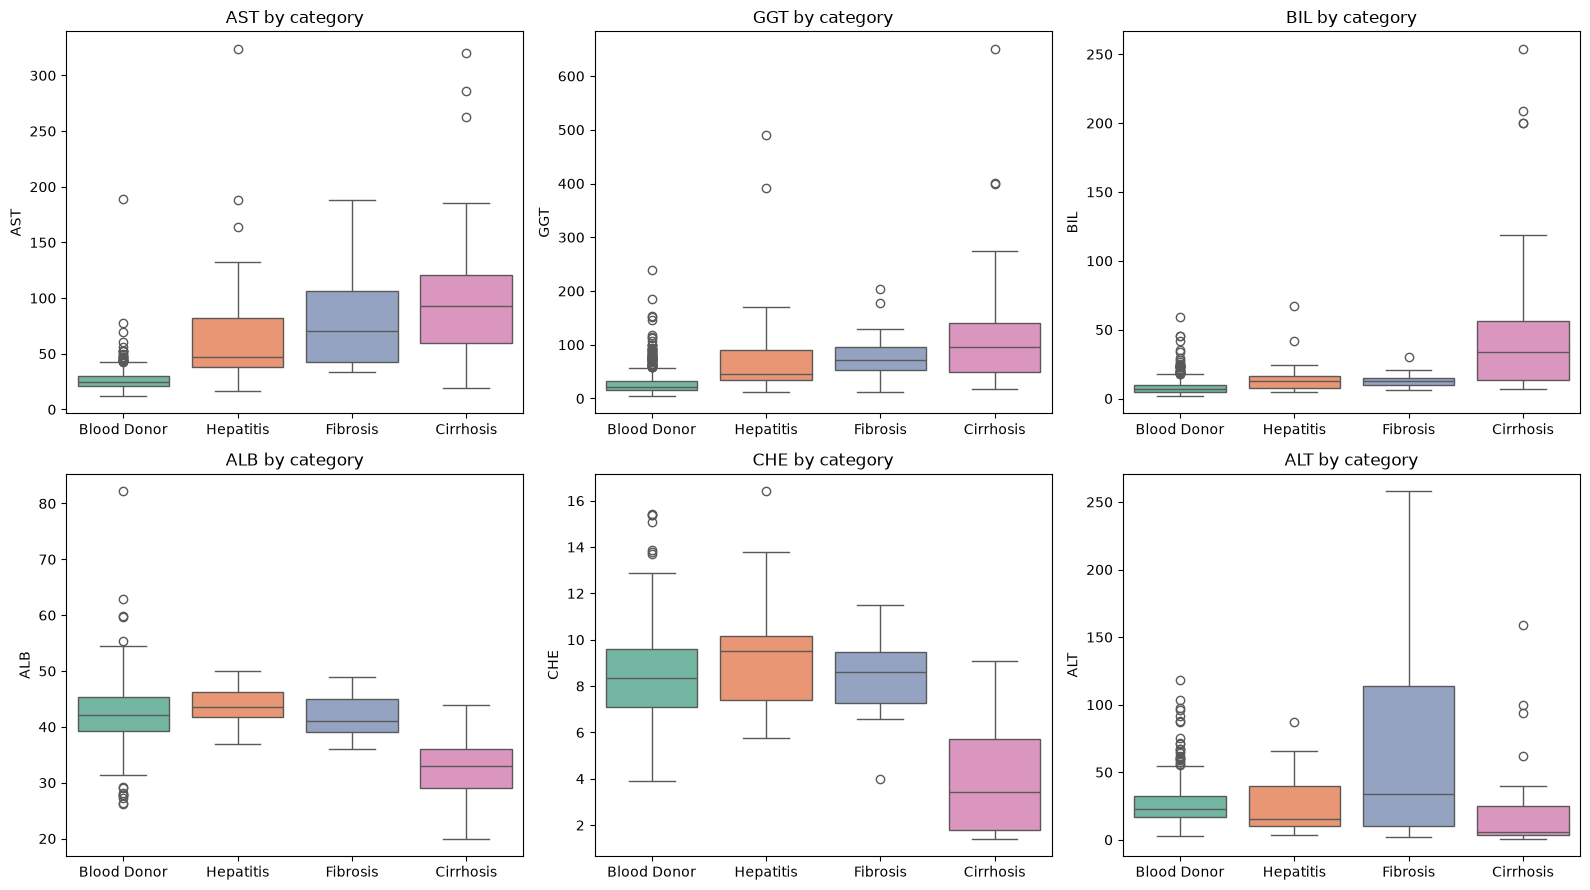

In [9]:
# Box plots of the six labs that move the most, by category
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, lab in zip(axes.ravel(), ['AST', 'GGT', 'BIL', 'ALB', 'CHE', 'ALT']):
    sns.boxplot(data=hepatitis, x='Category', y=lab, order=CLASSES, hue='Category', palette='Set2', ax=ax, legend=False)
    ax.set_title(lab + ' by category')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

Each panel shows one lab with a box per category. The box holds the middle half of the people, the line inside is the median, the whiskers reach the values still close to the box and the dots beyond are the extremes.

For `AST`, `GGT` and `BIL` the donor box is a thin strip near the bottom and the cirrhosis box sits well above it, but the dots above the donor whiskers reach the same heights as the sick boxes, so a few donors have values that look sick. For `ALB` and `CHE` the cirrhosis box sits clearly below the other three, which overlap almost entirely. The hepatitis and fibrosis boxes overlap in every panel, which is what the medians already said.

Imbalance (skew) of each lab:
CREA    15.36
BIL      8.35
GGT      6.11
AST      5.14
ALP      4.88
ALT      4.18
CHOL     0.40
ALB      0.29
CHE     -0.16
PROT    -0.40
dtype: float64


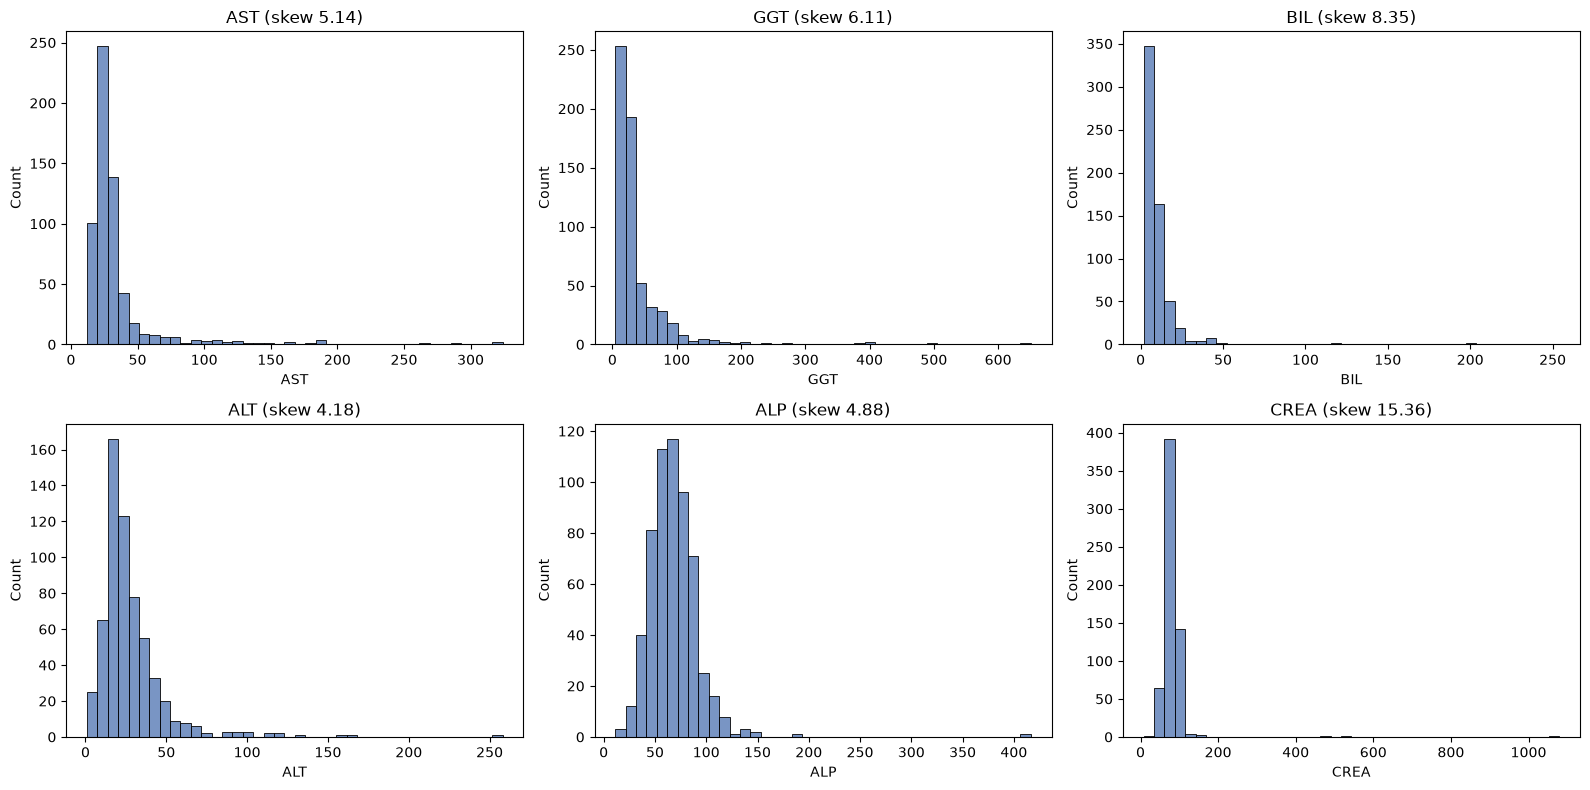

In [10]:
# Shape of each lab: 0 means a symmetric bell, positive means a tail to the
# right, and beyond 1 the column is clearly unbalanced
skewness = hepatitis[LABS].skew().sort_values(ascending=False)
print("Imbalance (skew) of each lab:")
print(skewness.round(2))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, lab in zip(axes.ravel(), ['AST', 'GGT', 'BIL', 'ALT', 'ALP', 'CREA']):
    sns.histplot(hepatitis[lab], bins=40, ax=ax, color='#4c72b0')
    ax.set_title(lab + ' (skew %.2f)' % skewness[lab])
plt.tight_layout()
plt.show()

The skew is a number that says how unbalanced a histogram is, with 0 for a symmetric bell, a positive value for a tail on the right, and anything past 1 clearly unbalanced. Six labs are far past that boundary: `CREA` at 15.4, `BIL` at 8.4, `GGT` at 6.1, `AST` at 5.1, `ALP` at 4.9 and `ALT` at 4.2. The histograms show it: every one of them is a tall spike on the left with a thin tail running to the right, nothing like a bell.

This matters for the technique. Gaussian Naive Bayes describes each lab inside each class with a mean and a standard deviation, that is, with a bell, and computes how likely a value is under that bell. When the real shape is a spike with a long tail, the bell fitted to it is wide and centred too far to the right, so a mildly high value looks ordinary and an ordinary value looks slightly abnormal. The standard fix is to take the logarithm, which pulls the tail in and turns a spike with a tail into something close to a bell. Both versions are fitted below.

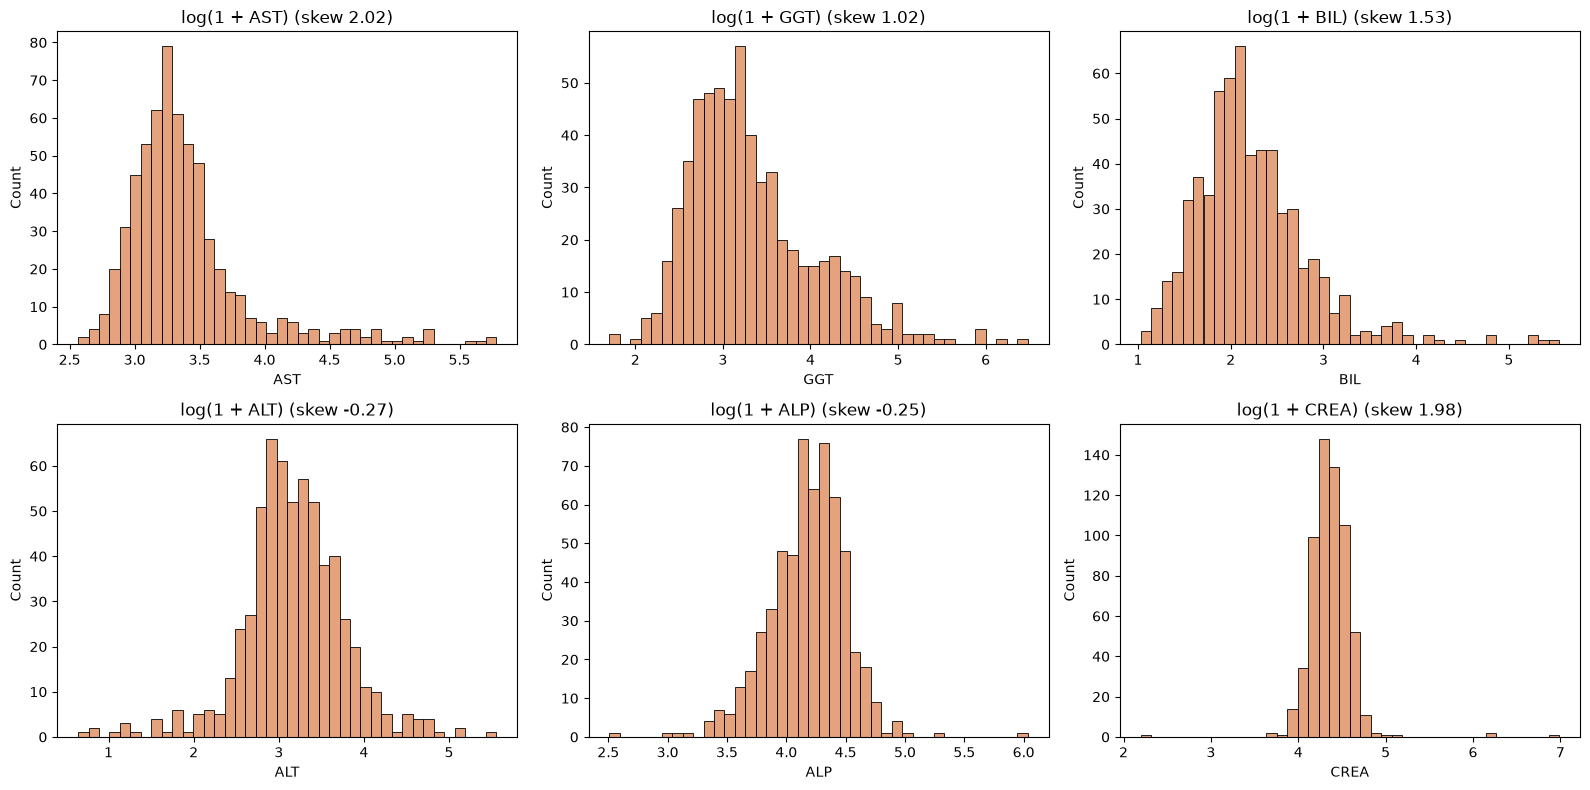

In [11]:
# The same six labs after the logarithm. log1p is log(1 + x), so a value of 0 is handled
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, lab in zip(axes.ravel(), ['AST', 'GGT', 'BIL', 'ALT', 'ALP', 'CREA']):
    logged = np.log1p(hepatitis[lab])
    sns.histplot(logged, bins=40, ax=ax, color='#dd8452')
    ax.set_title('log(1 + %s) (skew %.2f)' % (lab, logged.skew()))
plt.tight_layout()
plt.show()

After the logarithm the same six columns are rounded humps with a skew between about -0.5 and 1.5, instead of 4.2 to 15.4. `CREA` keeps a visible tail on both sides because its extremes are a handful of kidney patients, but even it is far closer to a bell than before. This is the shape Gaussian Naive Bayes expects, and it is why Model B works in log space.

In [12]:
# Preparation: fill the missing labs with the median, encode sex, define the predictors
FILL_VALUES = hepatitis[LABS].median().to_dict()
hepatitis[LABS] = hepatitis[LABS].fillna(FILL_VALUES)
hepatitis['Sex'] = (hepatitis['Sex'] == 'm').astype(int)

FEATURES = ['Age', 'Sex'] + LABS
TARGET = 'Category'
print("Missing values left:", int(hepatitis[FEATURES].isna().sum().sum()))
print("Predictors:", FEATURES)
hepatitis[FEATURES + [TARGET]].head()

Missing values left: 0
Predictors: ['Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']


,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,Category
0,32,1,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,Blood Donor
1,32,1,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,Blood Donor
2,32,1,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,Blood Donor
3,32,1,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,Blood Donor
4,32,1,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,Blood Donor


The table is now complete and numeric, with `Sex` coded 1 for male, twelve predictors and the four-category target. The fill values are kept so the REST API can apply the same ones to a panel with a missing lab.

In [13]:
# Stratified 75 / 25 split, so each side keeps the proportion of every category
X = hepatitis[FEATURES]
y = hepatitis[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print("Training people per category:")
print(y_train.value_counts().reindex(CLASSES))
print()
print("Test people per category:")
print(y_test.value_counts().reindex(CLASSES))

Training people per category:
Category
Blood Donor    400
Hepatitis       18
Fibrosis        16
Cirrhosis       22
Name: count, dtype: int64

Test people per category:
Category
Blood Donor    133
Hepatitis        6
Fibrosis         5
Cirrhosis        8
Name: count, dtype: int64


The split is stratified so that every category is present on both sides in the same proportion, and it still leaves the test set with 6 hepatitis, 5 fibrosis and 8 cirrhosis patients. Those counts are too small to read a percentage from: one patient more or less moves the recall of fibrosis by 20 points. The evaluation therefore reports the held-out split, since that is the honest first look, and then a five-fold cross-validation, which fits the model five times, each time on four fifths of the people and predicting the remaining fifth, so that every one of the 608 people is predicted once by a model that never saw them. The cross-validated matrix covers all 24, 21 and 30 sick patients and is the number to trust.

## Machine Learning Model (CRISP-DM 4: Modeling)

Model A is Gaussian Naive Bayes on the labs as they come, the literal application of the technique. Model B applies the logarithm to every predictor first and then fits the same classifier. Both are fitted on the same training people and scored the same way.

In [14]:
# Evaluation helpers shared by both models
CROSS_VALIDATION = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def score_table(name, y_true, y_pred):
    return pd.Series({
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_true, y_pred),
        'Recall Hepatitis': recall_score(y_true, y_pred, labels=['Hepatitis'], average='macro', zero_division=0),
        'Recall Fibrosis': recall_score(y_true, y_pred, labels=['Fibrosis'], average='macro', zero_division=0),
        'Recall Cirrhosis': recall_score(y_true, y_pred, labels=['Cirrhosis'], average='macro', zero_division=0),
    }, name=name)

def show_confusion(y_true, y_pred, title, ax):
    matrix = confusion_matrix(y_true, y_pred, labels=CLASSES)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_xlabel('Predicted category')
    ax.set_ylabel('Real category')
    ax.set_title(title)

### Model A: Gaussian Naive Bayes on the raw labs

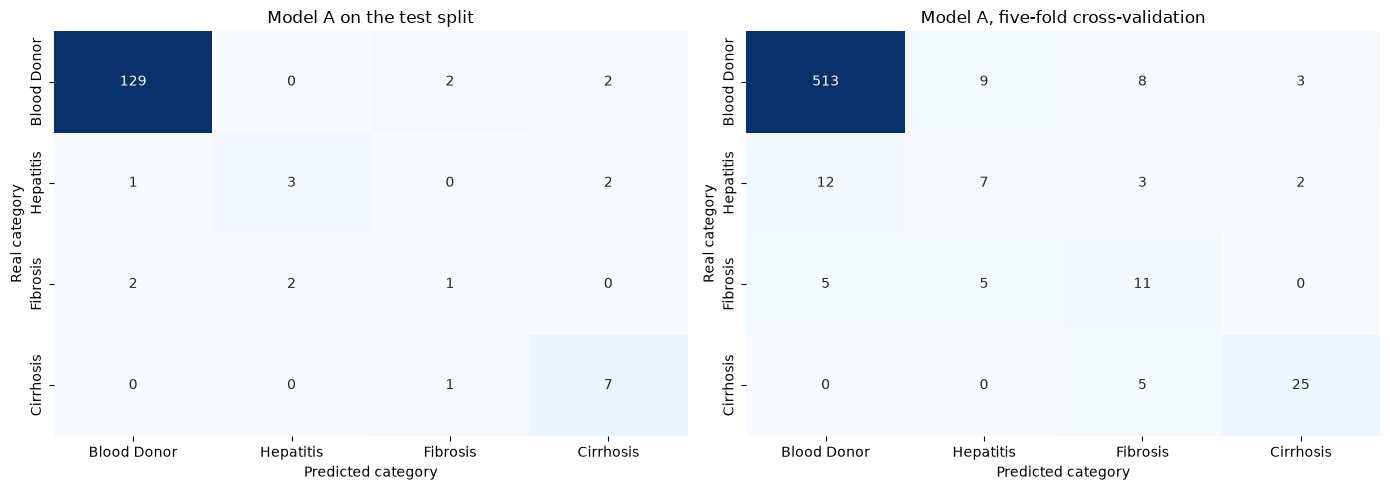

                   Test split  Cross-validation
Accuracy                0.921             0.914
Balanced accuracy       0.636             0.653
Recall Hepatitis        0.500             0.292
Recall Fibrosis         0.200             0.524
Recall Cirrhosis        0.875             0.833


In [15]:
model_raw = GaussianNB().fit(X_train, y_train)
pred_raw_test = model_raw.predict(X_test)
pred_raw_cv = cross_val_predict(GaussianNB(), X, y, cv=CROSS_VALIDATION)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
show_confusion(y_test, pred_raw_test, 'Model A on the test split', axes[0])
show_confusion(y, pred_raw_cv, 'Model A, five-fold cross-validation', axes[1])
plt.tight_layout()
plt.show()

print(pd.concat([score_table('Test split', y_test, pred_raw_test),
                 score_table('Cross-validation', y, pred_raw_cv)], axis=1).round(3))

A confusion matrix has the real category in rows and the predicted one in columns, so the diagonal holds the correct answers and every other cell is a mistake, read as "was this, called that". Accuracy is the share of the diagonal, and balanced accuracy is the average of the recall of the four classes, so it treats the 21 fibrosis patients as worth as much as the 533 donors. Recall of a class is the share of its real patients that the model called correctly.

On the test split the raw model finds 3 of the 6 hepatitis patients, 1 of the 5 fibrosis patients and 7 of the 8 cirrhosis patients, and those fractions are exactly the kind of number that a single patient can flip, which is why the cross-validated matrix is read instead. On that matrix, which is the stable one, the raw model calls 513 of the 533 donors correctly and 25 of the 30 cirrhosis patients, but only 7 of the 24 hepatitis patients and 11 of the 21 fibrosis patients. Twelve hepatitis patients are called donors. The accuracy of 0.914 is only a little above the 0.88 of answering donor to everyone, and the balanced accuracy of 0.653 says the model gets the average class right about two thirds of the time. The fitted bells are the reason: for a donor, `AST` has a mean of 26 but a standard deviation inflated by the handful of donors with values above 100, so a hepatitis patient at 47 looks like an ordinary donor to the model.

### Model B: Gaussian Naive Bayes on the logarithm of the labs

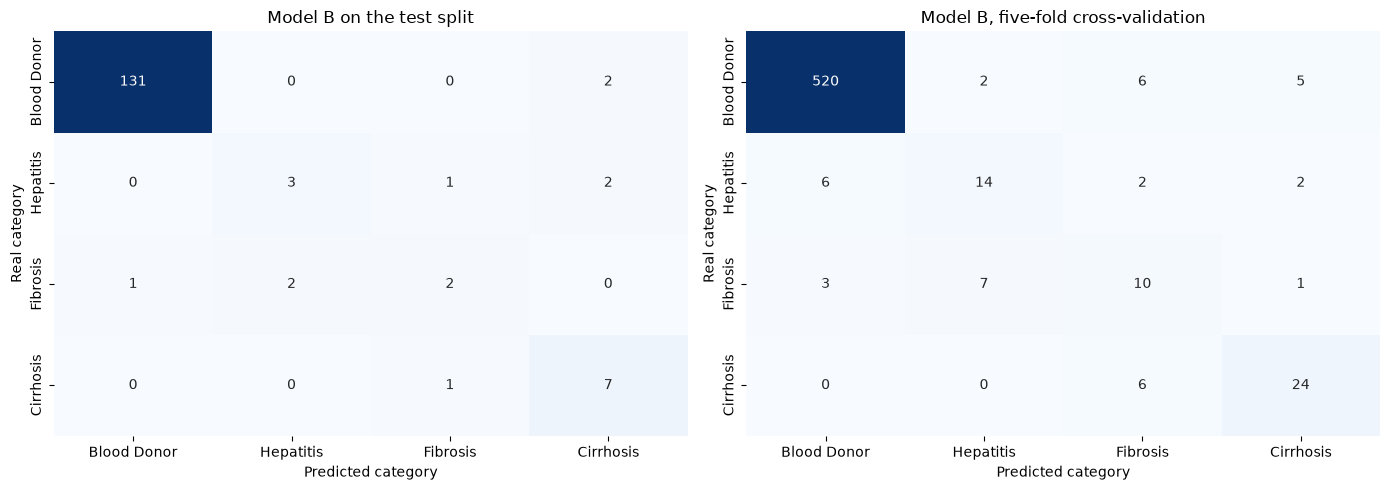

                   Test split  Cross-validation
Accuracy                0.941             0.934
Balanced accuracy       0.690             0.709
Recall Hepatitis        0.500             0.583
Recall Fibrosis         0.400             0.476
Recall Cirrhosis        0.875             0.800


In [16]:
def log_naive_bayes():
    return Pipeline([
        ('log', FunctionTransformer(np.log1p)),
        ('naive_bayes', GaussianNB()),
    ])

model_log = log_naive_bayes().fit(X_train, y_train)
pred_log_test = model_log.predict(X_test)
pred_log_cv = cross_val_predict(log_naive_bayes(), X, y, cv=CROSS_VALIDATION)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
show_confusion(y_test, pred_log_test, 'Model B on the test split', axes[0])
show_confusion(y, pred_log_cv, 'Model B, five-fold cross-validation', axes[1])
plt.tight_layout()
plt.show()

print(pd.concat([score_table('Test split', y_test, pred_log_test),
                 score_table('Cross-validation', y, pred_log_cv)], axis=1).round(3))

With the labs in log space the cross-validated matrix improves where it mattered. Hepatitis goes from 7 to 14 of 24 found, and the hepatitis patients called donors drop from 12 to 6. Donors called correctly rise from 513 to 520. Fibrosis stays hard, 10 of 21, with 7 of its patients called hepatitis, and cirrhosis loses one, 24 of 30, with 6 called fibrosis. Accuracy rises from 0.914 to 0.934 and balanced accuracy from 0.653 to 0.709. The gain comes entirely from the bells now fitting the data: after the logarithm the donor `AST` is a tight hump and a hepatitis value stands out from it.

What remains wrong is the boundary between hepatitis and fibrosis, and the matrix is honest about it: the two classes are exchanged for each other more often than either is confused with a donor. The box plots showed their labs overlapping in every panel, and no transformation can separate two groups that sit on top of each other.

## Evaluation (CRISP-DM 5)

Model B is the one kept. Its full report follows, on the cross-validated predictions since those cover every patient, followed by a second reading of the same predictions that only asks whether the person is sick.

In [17]:
print("Model B, five-fold cross-validation, four categories")
print(classification_report(y, pred_log_cv, labels=CLASSES, zero_division=0))

Model B, five-fold cross-validation, four categories
              precision    recall  f1-score   support

 Blood Donor       0.98      0.98      0.98       533
   Hepatitis       0.61      0.58      0.60        24
    Fibrosis       0.42      0.48      0.44        21
   Cirrhosis       0.75      0.80      0.77        30

    accuracy                           0.93       608
   macro avg       0.69      0.71      0.70       608
weighted avg       0.94      0.93      0.94       608



The report gives each class its precision, the share of the people called that class who really are, its recall, the share of the real people of that class that were found, F1, which combines the two, and the support, the number of real people in the class. Donors reach 0.98 on every score. Cirrhosis reaches a recall of 0.80 with a precision of 0.75, so when the model says cirrhosis it is right three times out of four and it finds four cirrhosis patients out of five. Hepatitis gets 0.58 recall and 0.61 precision, and fibrosis 0.48 and 0.42, which are the two numbers a doctor should know before trusting the stage: for the middle stages the model is a hint, not a result. The macro average F1 of 0.70 summarises the four classes weighing them equally.

In [18]:
# The same predictions read as healthy against sick
sick_true = (y != 'Blood Donor').astype(int)
sick_pred = (pd.Series(pred_log_cv, index=y.index) != 'Blood Donor').astype(int)
tn, fp, fn, tp = confusion_matrix(sick_true, sick_pred).ravel()
print("Sick patients found:", tp, "of", tp + fn)
print("Sick patients called donors:", fn)
print("Donors called sick:", fp, "of", tn + fp)
print()
print(classification_report(sick_true, sick_pred, target_names=['Donor', 'Sick']))

Sick patients found: 66 of 75
Sick patients called donors: 9
Donors called sick: 13 of 533

              precision    recall  f1-score   support

       Donor       0.98      0.98      0.98       533
        Sick       0.84      0.88      0.86        75

    accuracy                           0.96       608
   macro avg       0.91      0.93      0.92       608
weighted avg       0.96      0.96      0.96       608



Read only as healthy or sick, the same model finds 66 of the 75 patients, a recall of 0.88, and calls 13 of the 533 donors sick, a precision for the sick class of 0.84. The 66 include patients given the wrong stage, since a hepatitis patient called fibrosis is still called sick. So the model is good at the question that matters first, whether the blood panel belongs to someone with liver disease, and weaker at the second question of which stage, mostly because it cannot tell hepatitis from fibrosis.

In [19]:
# Side by side on the cross-validated predictions
comparison = pd.concat([score_table('Model A: raw labs', y, pred_raw_cv),
                        score_table('Model B: log labs', y, pred_log_cv)], axis=1).round(3)
print(comparison)

                   Model A: raw labs  Model B: log labs
Accuracy                       0.914              0.934
Balanced accuracy              0.653              0.709
Recall Hepatitis               0.292              0.583
Recall Fibrosis                0.524              0.476
Recall Cirrhosis               0.833              0.800


Model B is better than Model A on accuracy, balanced accuracy and the recall of hepatitis, and worse on the recall of fibrosis, 0.476 against 0.524, and of cirrhosis, 0.800 against 0.833. That is the cost of the transformation, stated plainly: one fibrosis patient and one cirrhosis patient that the raw model got right, in exchange for seven more hepatitis patients found and a balanced accuracy that rises from 0.653 to 0.709. The two lost patients were not called donors, they were moved to the neighbouring stage, so they still reach a specialist, while the hepatitis patients the raw model missed were called donors and sent home. The trade favours Model B.

## Results (CRISP-DM 6: Deployment)

The model kept is a Gaussian Naive Bayes fitted on the logarithm of the age, the sex and the ten labs of the panel, predicting one of four categories. Over the five-fold cross-validation of the 608 people it reaches an accuracy of 0.934 and a balanced accuracy of 0.709, with a recall of 0.98 for donors, 0.58 for hepatitis, 0.48 for fibrosis and 0.80 for cirrhosis. The literal model on the raw labs, built first, reaches 0.914 and 0.653, and it was replaced because the labs are spikes with long tails and the technique assumes bells, which the skew values and the histograms showed and the logarithm fixed.

The model is recommended for the assistant with its weakness stated: it separates donors from patients and it recognises cirrhosis, but the two middle stages are exchanged for each other about half of the time, and any answer of hepatitis or fibrosis should be read as "early stage liver disease" rather than as a stage. The other limitation is the size of the sick classes, 24, 21 and 30 people, which is why the numbers come from cross-validation rather than from a single test set. The pipeline is saved below with the predictor list, the class names and the median fill values so the REST API can complete a panel with a missing lab and predict without training.

In [20]:
bundle = {
    'model': model_log,
    'features': FEATURES,
    'target': TARGET,
    'classes': CLASSES,
    'fill_values': {lab: float(value) for lab, value in FILL_VALUES.items()},
}
MODEL_PATH = os.path.join(MODELS_DIR, 'hepatitis_type_classification.joblib')
joblib.dump(bundle, MODEL_PATH)
print("Saved to", MODEL_PATH)

Saved to ../models/hepatitis_type_classification.joblib


In [21]:
# Reload and classify one panel by hand: a 52 year old man with high AST, GGT and
# bilirubin and low albumin and cholinesterase, the pattern of cirrhosis
loaded = joblib.load(MODEL_PATH)
panel = pd.DataFrame([{
    'Age': 52, 'Sex': 1, 'ALB': 32.0, 'ALP': 70.0, 'ALT': 8.0, 'AST': 95.0, 'BIL': 30.0,
    'CHE': 3.5, 'CHOL': 4.0, 'CREA': 75.0, 'GGT': 100.0, 'PROT': 70.0,
}])[loaded['features']]
probabilities = pd.Series(loaded['model'].predict_proba(panel)[0], index=loaded['model'].classes_)
print("Predicted category:", loaded['model'].predict(panel)[0])
print(probabilities.round(3))

Predicted category: Cirrhosis
Blood Donor    0.0
Cirrhosis      1.0
Fibrosis       0.0
Hepatitis      0.0
dtype: float64


The reloaded pipeline calls this panel cirrhosis with a probability near 1, which is what the medians of that class said it should: AST near 93, GGT near 96, bilirubin near 34, albumin near 33 and cholinesterase near 3.4 are the cirrhosis profile. The API repeats this call: fill any missing lab with the stored median, order the twelve columns, and return the category with its probabilities.